# Eksperimen & Modeling Naive Bayes — Deteksi Situs Web Phishing
**PIC:** Gisca (Anggota 3 — Evaluator & Benchmark)  
**Dataset:** `dataset/output/` (4.679 train, 1.170 test, 30 fitur indikator keamanan)  
**Target:** `Result` (`0` = Legitimate / Aman, `1` = Phishing / Berbahaya)

**Kenapa Naive Bayes?** Naive Bayes adalah model probabilistik yang sangat ringan dan cepat. Model ini menghitung peluang sebuah situs termasuk phishing berdasarkan nilai tiap fitur, dengan asumsi "naif" bahwa antar-fitur saling bebas. Di tim, Naive Bayes dipakai sebagai **baseline** pembanding kecepatan dan akurasi.

Tahapan dalam notebook ini:
1. Memuat dataset bersama (tanpa split ulang).
2. Membandingkan 3 varian Naive Bayes (Gaussian, Bernoulli, Categorical) dengan *5-fold cross-validation* **hanya di data latih**.
3. Tuning parameter `alpha` untuk varian terbaik.
4. Evaluasi model terbaik pada data uji (Accuracy, Precision, Recall Phishing, F1, ROC-AUC, Confusion Matrix).
5. Menyimpan model ke `models/naive_bayes_model.pkl` dan metrik ke `evaluation/naive_bayes_metrics.json`.

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import BernoulliNB, CategoricalNB, GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

DATA_DIR = Path("../dataset/output")
MODEL_DIR = Path("../models")
EVAL_DIR = Path("../evaluation")
NB_DIR = EVAL_DIR / "naive_bayes"
MODEL_DIR.mkdir(exist_ok=True)
NB_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Memuat Dataset Bersama
Naive Bayes **tidak memakai** `scaler.pkl`, karena model ini tidak berbasis jarak. Data dipakai apa adanya dari `dataset/output/`.

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print("Proporsi y_train (0=Legitimate, 1=Phishing):", y_train.value_counts().to_dict())
print("Proporsi y_test  (0=Legitimate, 1=Phishing):", y_test.value_counts().to_dict())
print("Nilai unik semua fitur:", sorted(np.unique(X_train.values)))

X_train: (4679, 30) | X_test: (1170, 30)
Proporsi y_train (0=Legitimate, 1=Phishing): {1: 2415, 0: 2264}
Proporsi y_test  (0=Legitimate, 1=Phishing): {1: 604, 0: 566}
Nilai unik semua fitur: [np.int64(-1), np.int64(0), np.int64(1)]


Semua fitur hanya bernilai **-1 (indikator phishing), 0 (mencurigakan), atau 1 (indikator aman)**. Artinya fitur ini **kategorikal/diskrit**, bukan angka kontinu.

## 2. Membandingkan 3 Varian Naive Bayes
| Varian | Asumsi data | Cocok untuk dataset ini? |
|---|---|---|
| **GaussianNB** | Fitur kontinu berdistribusi normal | Kurang cocok, fitur kita hanya 3 nilai |
| **BernoulliNB** | Fitur biner (ya/tidak) | Sebagian; nilai `0` (mencurigakan) ikut digabung |
| **CategoricalNB** | Fitur kategori diskrit | Paling cocok secara teori |

`CategoricalNB` butuh kategori berupa angka 0, 1, 2, ... Karena itu kita pasang `OrdinalEncoder` di dalam *pipeline* yang mengubah -1→0, 0→1, 1→2. Karena encoder ada di dalam pipeline, aplikasi Streamlit tetap bisa mengirim data mentah (-1/0/1) langsung ke model.

Pemilihan varian memakai **5-fold cross-validation di data latih saja**, supaya data uji tetap "bersih" dan hanya dipakai sekali di akhir.

In [3]:
def make_categorical_nb(alpha=1.0):
    encoder = OrdinalEncoder(
        categories=[[-1, 0, 1]] * X_train.shape[1],  # urutan kategori tetap untuk ke-30 fitur
    )
    return Pipeline([
        ("encoder", encoder),
        ("nb", CategoricalNB(alpha=alpha, min_categories=3)),
    ])

kandidat = {
    "GaussianNB": GaussianNB(),
    "BernoulliNB": BernoulliNB(binarize=0.0),  # 1 -> aman, -1 & 0 -> tidak aman
    "CategoricalNB": make_categorical_nb(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC_AUC": "roc_auc"}

hasil_cv = []
for nama, model in kandidat.items():
    skor = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    baris = {"Varian": nama}
    for m in scoring:
        baris[m] = skor[f"test_{m}"].mean()
    hasil_cv.append(baris)

cv_df = pd.DataFrame(hasil_cv).set_index("Varian").round(4)
cv_df

,Accuracy,Precision,Recall,F1,ROC_AUC
Varian,,,,,
GaussianNB,0.6625,0.6049,0.9988,0.7534,0.9649
BernoulliNB,0.8989,0.8921,0.9151,0.9034,0.9592
CategoricalNB,0.9288,0.9401,0.9209,0.9303,0.9810


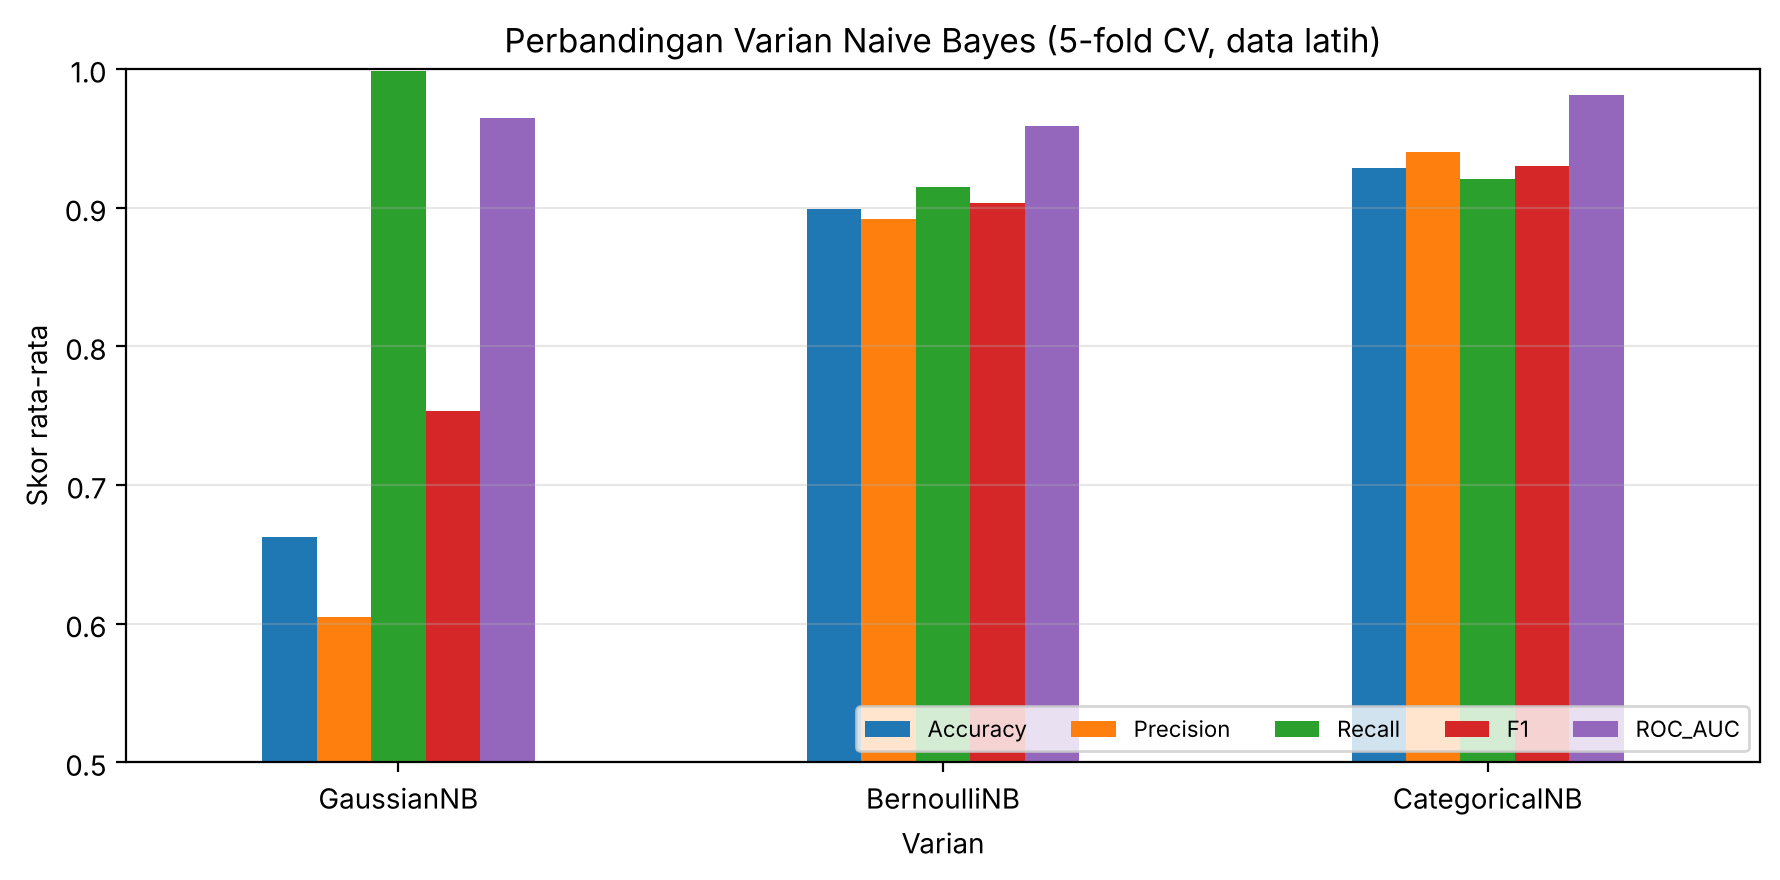

In [4]:
ax = cv_df.plot(kind="bar", figsize=(9, 4.5), rot=0, ylim=(0.5, 1.0))
ax.set_title("Perbandingan Varian Naive Bayes (5-fold CV, data latih)")
ax.set_ylabel("Skor rata-rata")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right", ncol=5, fontsize=8)
plt.tight_layout()
plt.savefig(NB_DIR / "perbandingan_varian_nb.png", dpi=150)
plt.show()

## 3. Tuning `alpha` (Laplace Smoothing)
`alpha` adalah "smoothing": angka kecil yang ditambahkan ke setiap hitungan supaya kategori yang jarang muncul tidak menghasilkan peluang 0. Kita coba beberapa nilai pada varian terbaik dari langkah 2, lagi-lagi dengan CV di data latih.

In [5]:
varian_terbaik = cv_df["F1"].idxmax()
print("Varian terbaik berdasarkan F1 (Phishing):", varian_terbaik)

def buat_model(varian, alpha):
    if varian == "CategoricalNB":
        return make_categorical_nb(alpha)
    if varian == "BernoulliNB":
        return BernoulliNB(alpha=alpha, binarize=0.0)
    return GaussianNB()

alphas = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0] if varian_terbaik != "GaussianNB" else [None]
hasil_alpha = []
for a in alphas:
    skor = cross_validate(buat_model(varian_terbaik, a), X_train, y_train, cv=cv, scoring=scoring)
    hasil_alpha.append({"alpha": a, **{m: skor[f"test_{m}"].mean() for m in scoring}})

alpha_df = pd.DataFrame(hasil_alpha).round(4)
best_alpha = alpha_df.sort_values(["F1", "ROC_AUC"], ascending=False).iloc[0]["alpha"]
print("alpha terbaik:", best_alpha)
alpha_df

Varian terbaik berdasarkan F1 (Phishing): CategoricalNB


alpha terbaik: 2.0


,alpha,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.01,0.9288,0.9401,0.9209,0.9303,0.9811
1,0.10,0.9288,0.9401,0.9209,0.9303,0.9811
2,0.50,0.9288,0.9401,0.9209,0.9303,0.9810
3,1.00,0.9288,0.9401,0.9209,0.9303,0.9810
4,2.00,0.9290,0.9405,0.9209,0.9305,0.9809
5,5.00,0.9290,0.9405,0.9209,0.9305,0.9807


## 4. Pelatihan & Evaluasi Model Terbaik pada Data Uji
Model final dilatih ulang di **seluruh data latih**, lalu diuji **satu kali** di data uji.

Ingat: untuk sistem keamanan, **Recall Phishing** paling penting. Recall rendah berarti banyak situs phishing yang lolos dan dianggap aman (*False Negative*).

In [6]:
best_model = buat_model(varian_terbaik, best_alpha)

t0 = time.perf_counter()
best_model.fit(X_train, y_train)
train_time = time.perf_counter() - t0

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Classification Report (0 = Legitimate, 1 = Phishing):")
print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"], digits=4))
print(f"ROC-AUC     : {roc_auc_score(y_test, y_proba):.4f}")
print(f"Waktu latih : {train_time:.4f} detik")

with open(NB_DIR / "classification_report_nb.txt", "w", encoding="utf-8") as f:
    f.write(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"], digits=4))

Classification Report (0 = Legitimate, 1 = Phishing):
                precision    recall  f1-score   support

Legitimate (0)     0.9080    0.9417    0.9245       566
  Phishing (1)     0.9434    0.9106    0.9267       604

      accuracy                         0.9256      1170
     macro avg     0.9257    0.9261    0.9256      1170
  weighted avg     0.9263    0.9256    0.9257      1170

ROC-AUC     : 0.9799
Waktu latih : 0.0198 detik


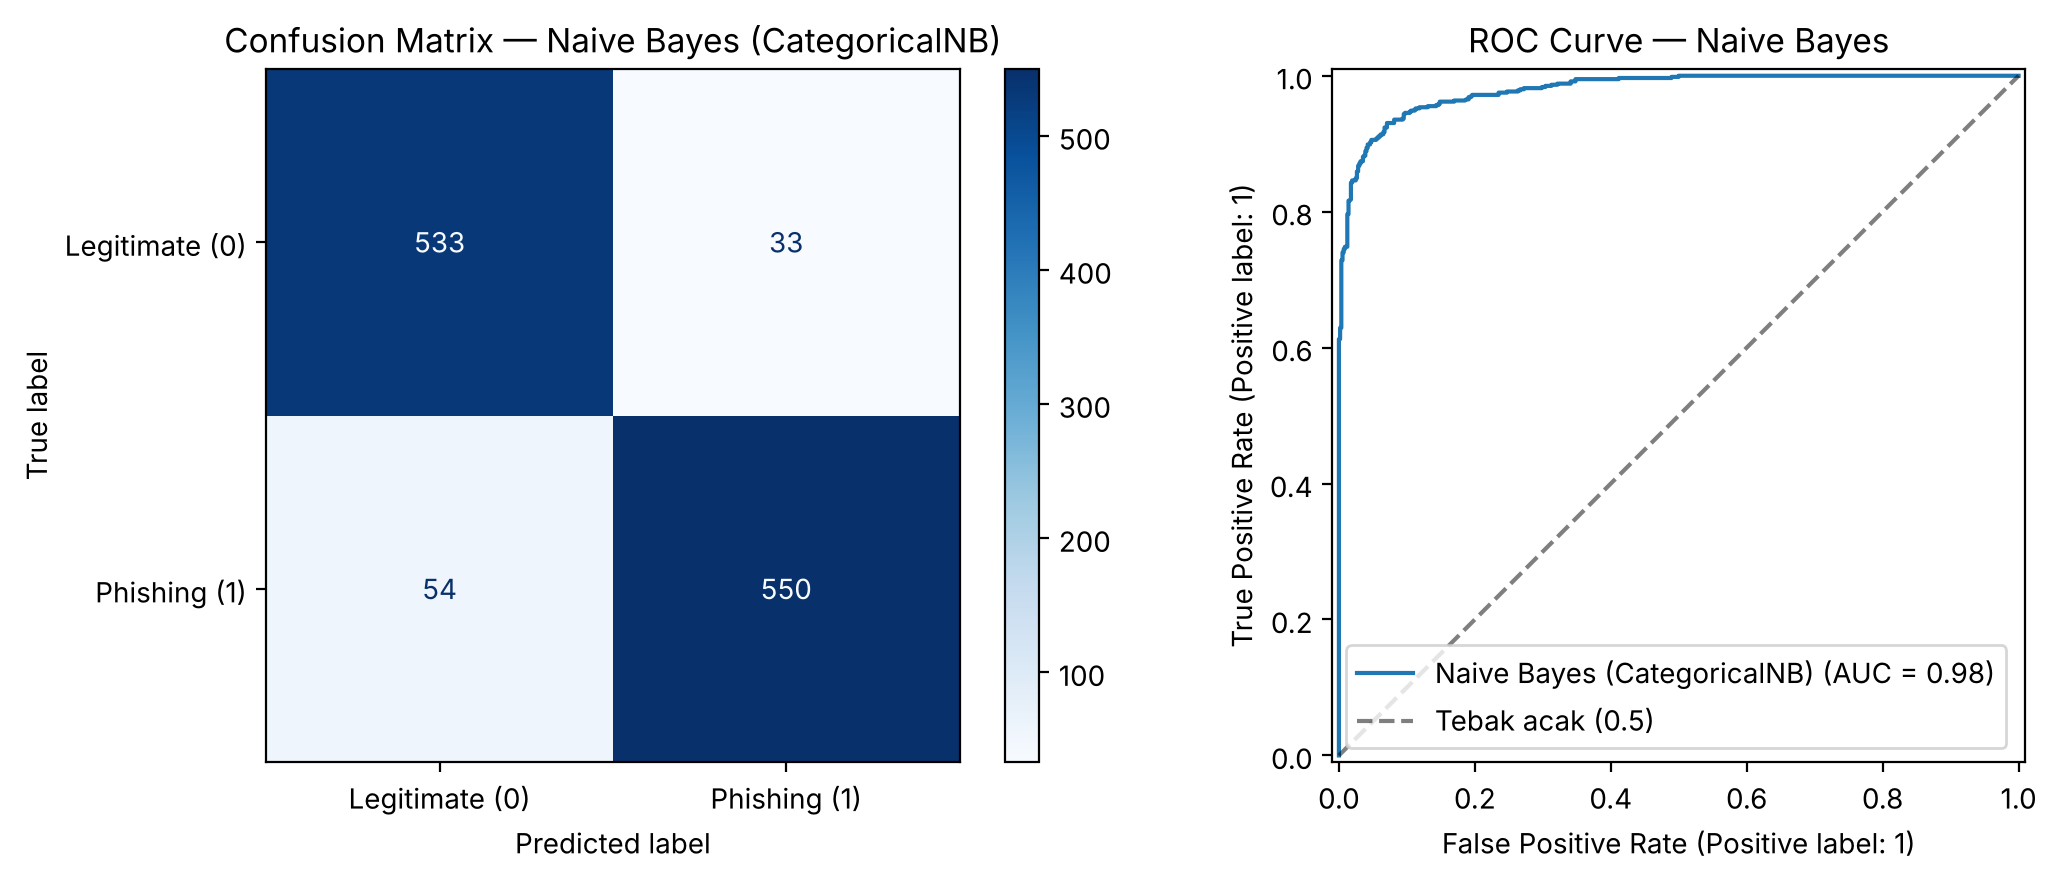

Phishing terdeteksi benar (TP) : 550
Phishing LOLOS dianggap aman (FN): 54  <- yang paling berbahaya
Situs aman kena peringatan (FP): 33
Situs aman benar (TN)          : 533


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Legitimate (0)", "Phishing (1)"],
    cmap="Blues", ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix — Naive Bayes ({varian_terbaik})")

RocCurveDisplay.from_predictions(y_test, y_proba, name=f"Naive Bayes ({varian_terbaik})", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Tebak acak (0.5)")
axes[1].set_title("ROC Curve — Naive Bayes")
axes[1].legend()

plt.tight_layout()
plt.savefig(NB_DIR / "confusion_matrix_roc_nb.png", dpi=150)
plt.show()

tn, fp, fn, tp = pd.crosstab(y_test, y_pred).values.ravel()
print(f"Phishing terdeteksi benar (TP) : {tp}")
print(f"Phishing LOLOS dianggap aman (FN): {fn}  <- yang paling berbahaya")
print(f"Situs aman kena peringatan (FP): {fp}")
print(f"Situs aman benar (TN)          : {tn}")

### Distribusi Probabilitas Phishing
Grafik ini menunjukkan seberapa "yakin" model. Idealnya situs aman menumpuk di dekat 0 dan situs phishing di dekat 1.

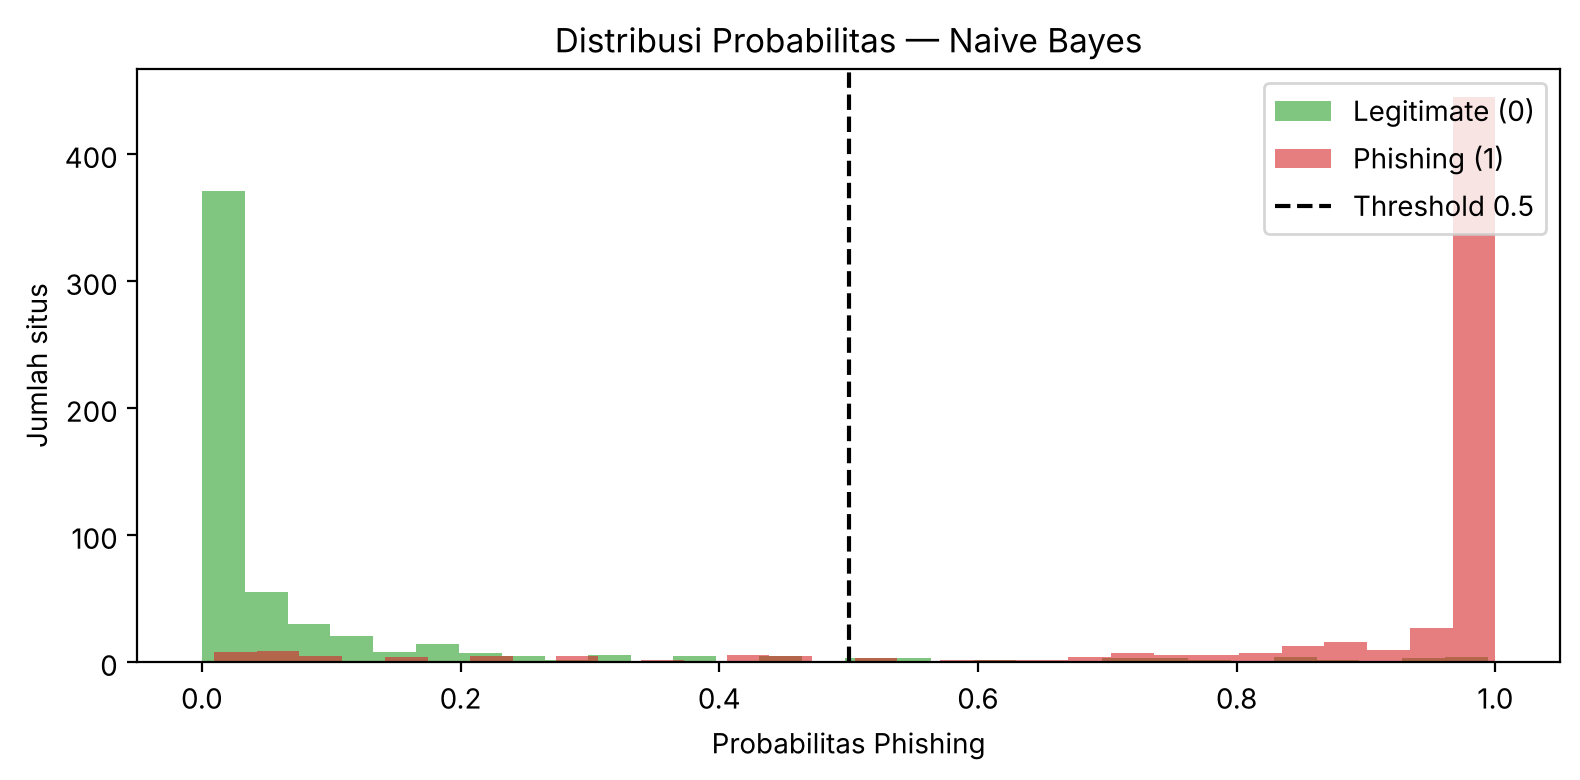

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_proba[y_test == 0], bins=30, alpha=0.6, label="Legitimate (0)", color="tab:green")
ax.hist(y_proba[y_test == 1], bins=30, alpha=0.6, label="Phishing (1)", color="tab:red")
ax.axvline(0.5, color="k", linestyle="--", label="Threshold 0.5")
ax.set_xlabel("Probabilitas Phishing")
ax.set_ylabel("Jumlah situs")
ax.set_title("Distribusi Probabilitas — Naive Bayes")
ax.legend()
plt.tight_layout()
plt.savefig(NB_DIR / "distribusi_probabilitas_nb.png", dpi=150)
plt.show()

## 5. Simpan Model & Metrik Evaluasi
- Model → `models/naive_bayes_model.pkl` (dibaca otomatis oleh aplikasi Streamlit, tanpa scaler).
- Metrik ringkas → `evaluation/naive_bayes_metrics.json` (format sama dengan KNN & Logistic Regression).
- Prediksi per baris → `evaluation/naive_bayes/prediksi_naive_bayes.csv` (dipakai untuk grafik komparasi 5 model).

In [9]:
joblib.dump(best_model, MODEL_DIR / "naive_bayes_model.pkl")

params = {"varian": varian_terbaik}
if best_alpha is not None and not pd.isna(best_alpha):
    params["alpha"] = float(best_alpha)
if varian_terbaik == "CategoricalNB":
    params["encoder"] = "OrdinalEncoder (-1,0,1 -> 0,1,2)"

metrics_summary = {
    "Algoritma": f"Naive Bayes ({varian_terbaik})",
    "PIC": "Gisca",
    "best_params": params,
    "Accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
    "Precision (Phishing)": round(float(precision_score(y_test, y_pred, pos_label=1)), 4),
    "Recall (Phishing)": round(float(recall_score(y_test, y_pred, pos_label=1)), 4),
    "F1-Score (Phishing)": round(float(f1_score(y_test, y_pred, pos_label=1)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_proba)), 4),
    "Train Time (s)": round(float(train_time), 4),
}
with open(EVAL_DIR / "naive_bayes_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2)

pd.DataFrame({"y_true": y_test, "y_pred": y_pred, "y_proba": y_proba.round(6)}).to_csv(
    NB_DIR / "prediksi_naive_bayes.csv", index=False
)
cv_df.to_csv(NB_DIR / "cv_varian_nb.csv")
alpha_df.to_csv(NB_DIR / "cv_alpha_nb.csv", index=False)

print(json.dumps(metrics_summary, indent=2))

{
  "Algoritma": "Naive Bayes (CategoricalNB)",
  "PIC": "Gisca",
  "best_params": {
    "varian": "CategoricalNB",
    "alpha": 2.0,
    "encoder": "OrdinalEncoder (-1,0,1 -> 0,1,2)"
  },
  "Accuracy": 0.9256,
  "Precision (Phishing)": 0.9434,
  "Recall (Phishing)": 0.9106,
  "F1-Score (Phishing)": 0.9267,
  "ROC-AUC": 0.9799,
  "Train Time (s)": 0.0198
}


## 6. Kesimpulan Singkat
Lihat angka di atas untuk hasil final. Poin-poin untuk laporan:
- **CategoricalNB** secara teori paling sesuai karena semua fitur bernilai diskrit (-1, 0, 1); hasil CV di langkah 2 dipakai untuk membuktikannya.
- Naive Bayes sangat **cepat dilatih** (milidetik), cocok sebagai baseline.
- Kelemahannya adalah asumsi **independensi antar-fitur**. Pada data phishing banyak fitur saling berkaitan (mis. `SSLfinal_State` dan `HTTPS_token`), sehingga probabilitasnya cenderung ekstrem (terlalu yakin) dan performanya biasanya sedikit di bawah KNN/Logistic Regression/Random Forest.
- Perhatikan jumlah **False Negative** (phishing yang lolos), karena itu metrik prioritas tim.